# NorthStar Lab 3 demo: churn model (Track A) and RAG offers (Track B)

In [1]:
import json, sys, pathlib
import pandas as pd
from IPython.display import Image, display
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
EV = 'docs/lab3-evidence'

## Track A: graded run metrics

In [2]:
print(json.dumps(json.load(open(f'{EV}/evaluation_metrics.json')), indent=2))

{
  "auc_roc": 0.7846,
  "precision_top10": 0.7167,
  "recall_top10": 0.3258,
  "auc_vs_baseline": 0.0643,
  "baseline_auc": 0.7203,
  "lift_ci_low": 0.0446,
  "lift_ci_high": 0.084,
  "positive_rate_val": 0.22,
  "n_val_samples": 3000,
  "eval_timestamp": "2026-10-16T23:12:58.591185+00:00",
  "n_train_samples": 5949
}


In [3]:
pd.read_csv(f'{EV}/slice-evaluation.csv')

,tier,n,positives,auc,recall,too_small,recall_gap_flag,aggregate_recall
0,Bronze,1071,361,0.7606,0.4266,False,False,0.3258
1,Gold,483,52,0.7551,0.1154,False,True,0.3258
2,Platinum,307,21,0.8765,0.1429,True,True,0.3258
3,Silver,1139,226,0.7179,0.2301,False,False,0.3258


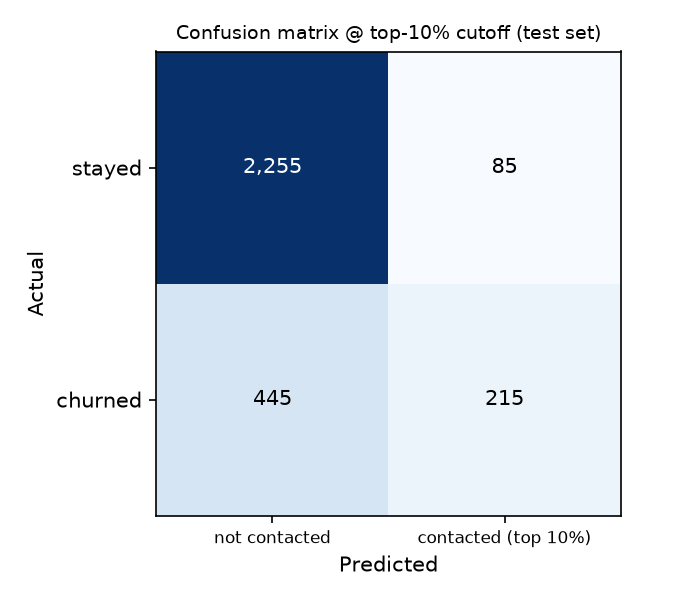

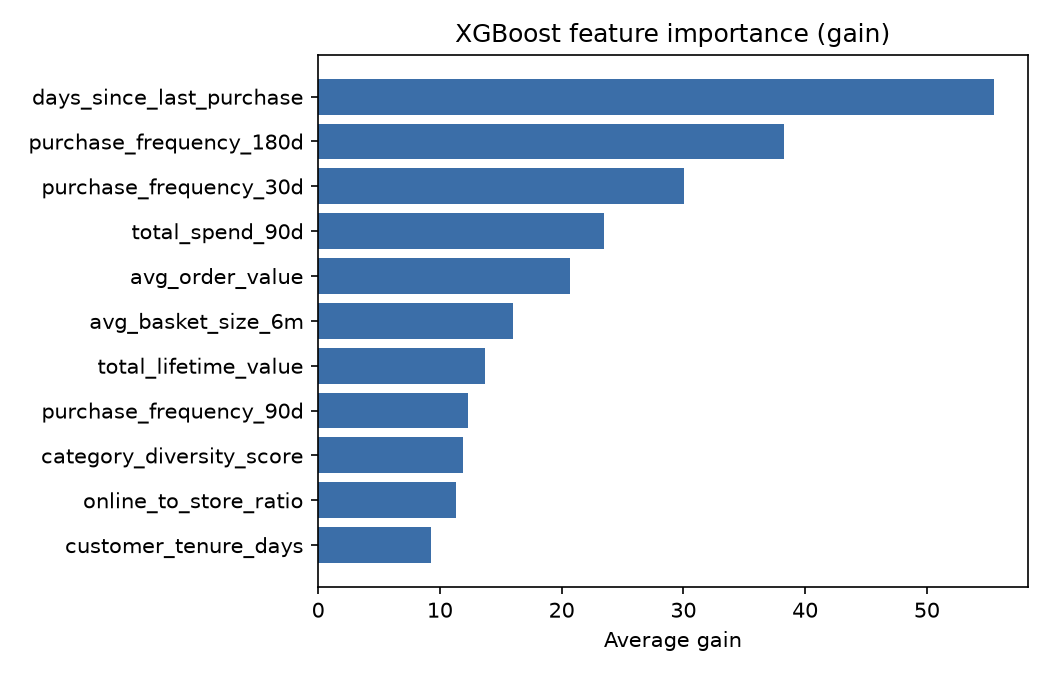

In [4]:
display(Image(f'{EV}/confusion-matrix.png')); display(Image(f'{EV}/feature-importance.png'))

## Track B: retention offers from the RAG pipeline

In [5]:
from rag.pipeline import generate_offer, SAMPLE_PROFILES

In [6]:
for p in SAMPLE_PROFILES:
    o = generate_offer(p)
    print(p['loyalty_tier'], p['top_categories'])
    print(' ', o['offer'])
    print('  chunks:', o['chunk_ids'], '\n')

Bronze ['Home', 'Toys']
  Your Bronze loyalty account earns points on every purchase, and those points don't expire as long as you keep shopping with us—your balance resets with each new order. We'd love to see you back in Home or Toys, where you've shopped before.
  chunks: ['loyalty-program-terms.md#4', 'customer-faq.md#2', 'loyalty-program-terms.md#3', 'customer-faq.md#7', 'return-policy.md#1', 'return-policy.md#0'] 



Silver ['Apparel', 'Footwear']
  As a Silver member, you earn points 25% faster on every purchase and get free standard shipping on orders over $50. We'd love to see you back shopping Apparel with us—your loyalty benefits make every purchase more rewarding.
  chunks: ['loyalty-program-terms.md#4', 'loyalty-program-terms.md#0', 'customer-faq.md#2', 'customer-faq.md#7', 'return-policy.md#1', 'return-policy.md#0'] 



Gold ['Electronics', 'Outdoor']
  Your Gold tier unlocks always-free standard shipping and free return shipping on every order, plus early access to our sales 24 hours before the general public. We'd love to have you back shopping Electronics with us.
  chunks: ['loyalty-program-terms.md#4', 'loyalty-program-terms.md#1', 'customer-faq.md#2', 'customer-faq.md#7', 'return-policy.md#1', 'return-policy.md#0'] 



Platinum ['Electronics', 'Home']
  As a Platinum member, you earn 2 points per $1 on all qualifying purchases, and your loyalty benefits include unlimited free gear repair and a $100 annual gear credit each January. We'd love to have you back shopping Electronics with us—your rewards add up fast at your tier.
  chunks: ['loyalty-program-terms.md#2', 'loyalty-program-terms.md#5', 'loyalty-program-terms.md#4', 'customer-faq.md#7', 'return-policy.md#1', 'return-policy.md#0'] 



Silver ['Beauty']
  Your Silver tier membership unlocks 12-hour early access to our sales and free standard shipping on orders over $50—benefits that reward your loyalty. We'd love to have you back shopping Beauty products with us.
  chunks: ['loyalty-program-terms.md#4', 'loyalty-program-terms.md#0', 'customer-faq.md#2', 'customer-faq.md#7', 'return-policy.md#1', 'return-policy.md#0'] 

